In [22]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import learning_curve
from sklearn.decomposition import PCA

In [2]:
diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df["target"] = diabetes.target
df.head()

print("Dimensioni del dataset:", df.shape)
df.info()

df.describe()

Dimensioni del dataset: (442, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


Il dataset contiene 442 osservazioni e 11 colonne, di cui 10 rappresentano le variabili indipendenti e una rappresenta la variabile target da prevedere.

Tutte le variabili sono numeriche, di tipo float64, e non sono presenti valori mancanti.

Le variabili indipendenti risultano già centrate e scalate, presentando medie prossime a zero e deviazioni standard simili.

La variabile target, che rappresenta una misura quantitativa della progressione della malattia dopo un anno, presenta una media di circa 152,13, una mediana di 140,50 e una deviazione standard di circa 77,09. I valori sono compresi tra un minimo di 25 e un massimo di 346.

La differenza tra media e mediana suggerisce una possibile asimmetria positiva della distribuzione della variabile target.

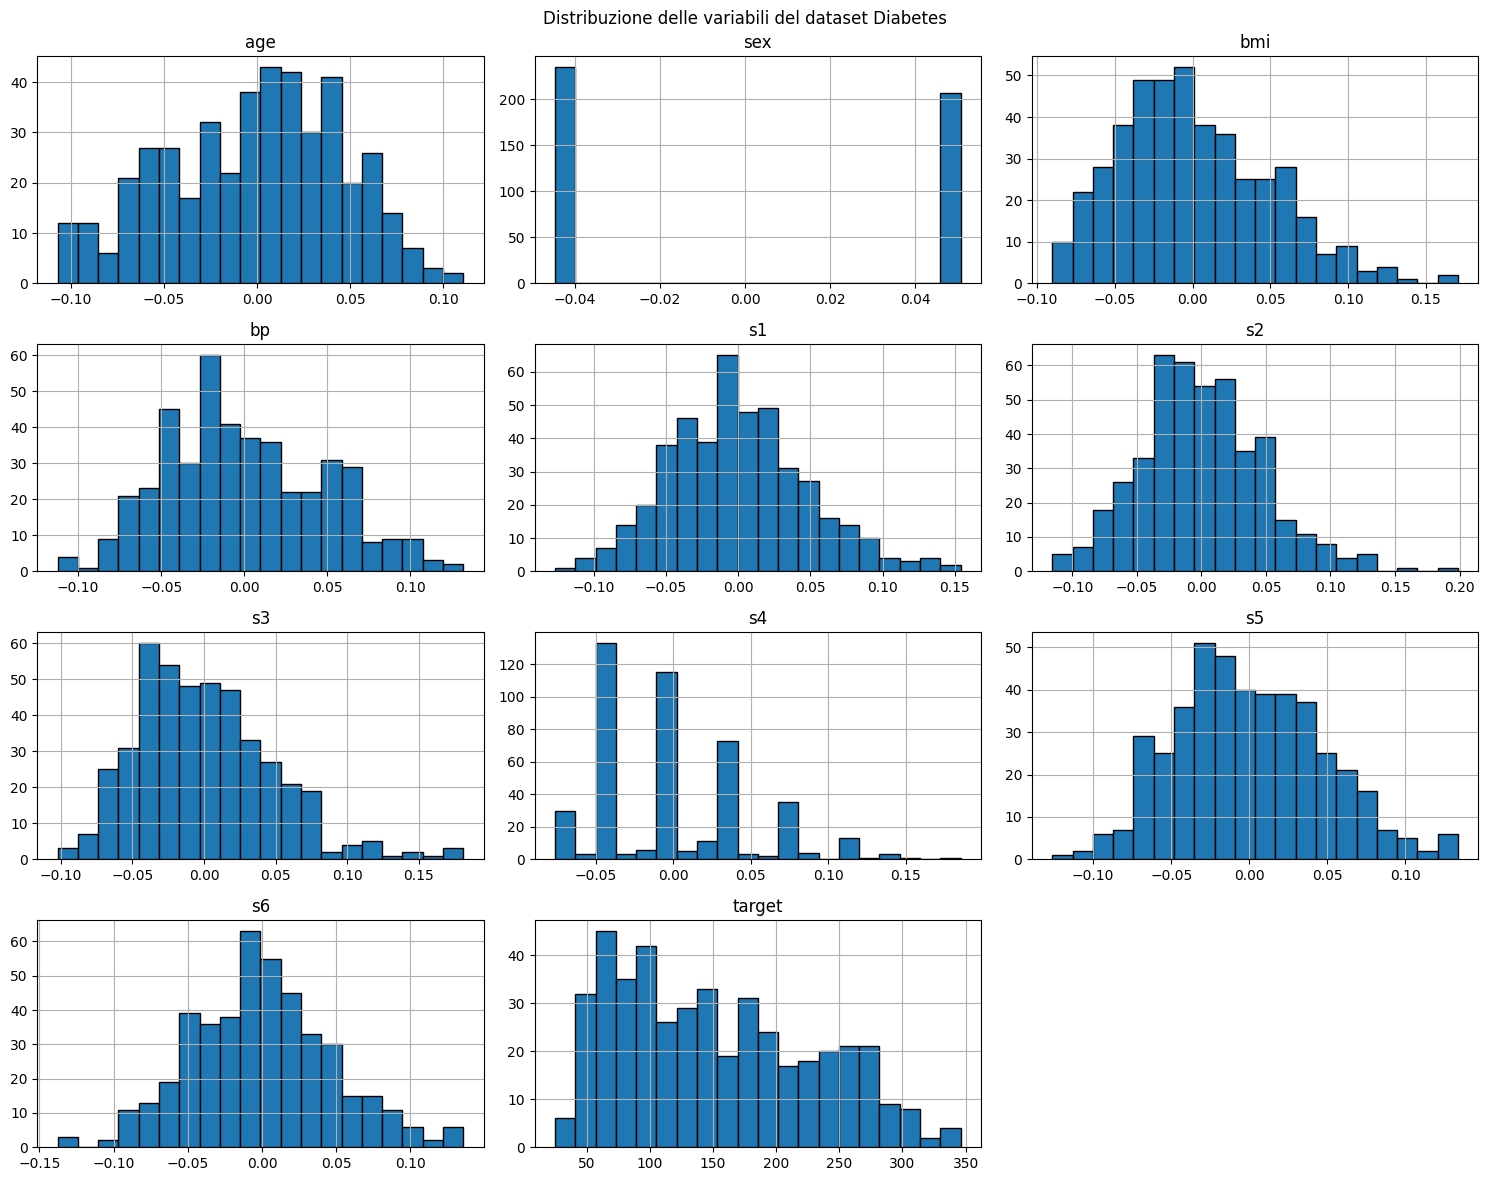

In [4]:
df.hist(figsize=(15, 12), bins=20, edgecolor="black")
plt.suptitle("Distribuzione delle variabili del dataset Diabetes")
plt.tight_layout()
plt.show()

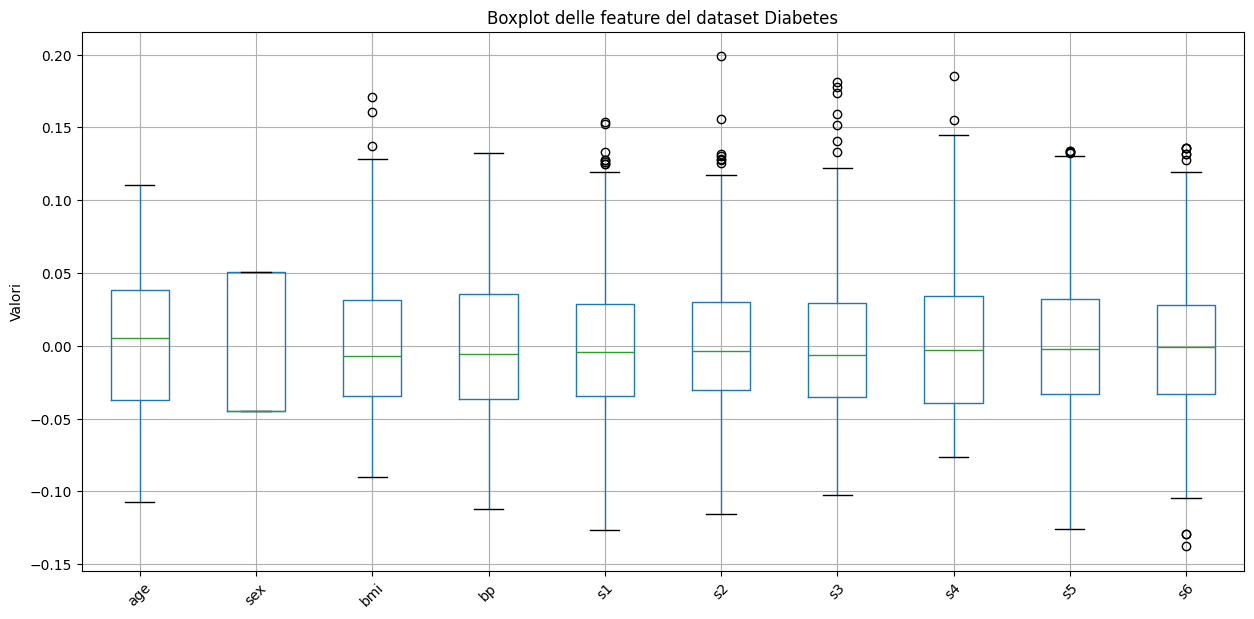

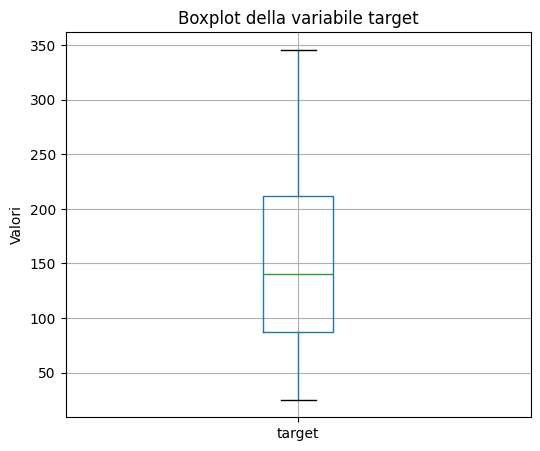

In [6]:

plt.figure(figsize=(15, 7))

df.drop(columns=["target"]).boxplot()

plt.title("Boxplot delle feature del dataset Diabetes")
plt.ylabel("Valori")
plt.xticks(rotation=45)
plt.show()


plt.figure(figsize=(6, 5))

df.boxplot(column="target")

plt.title("Boxplot della variabile target")
plt.ylabel("Valori")
plt.show()

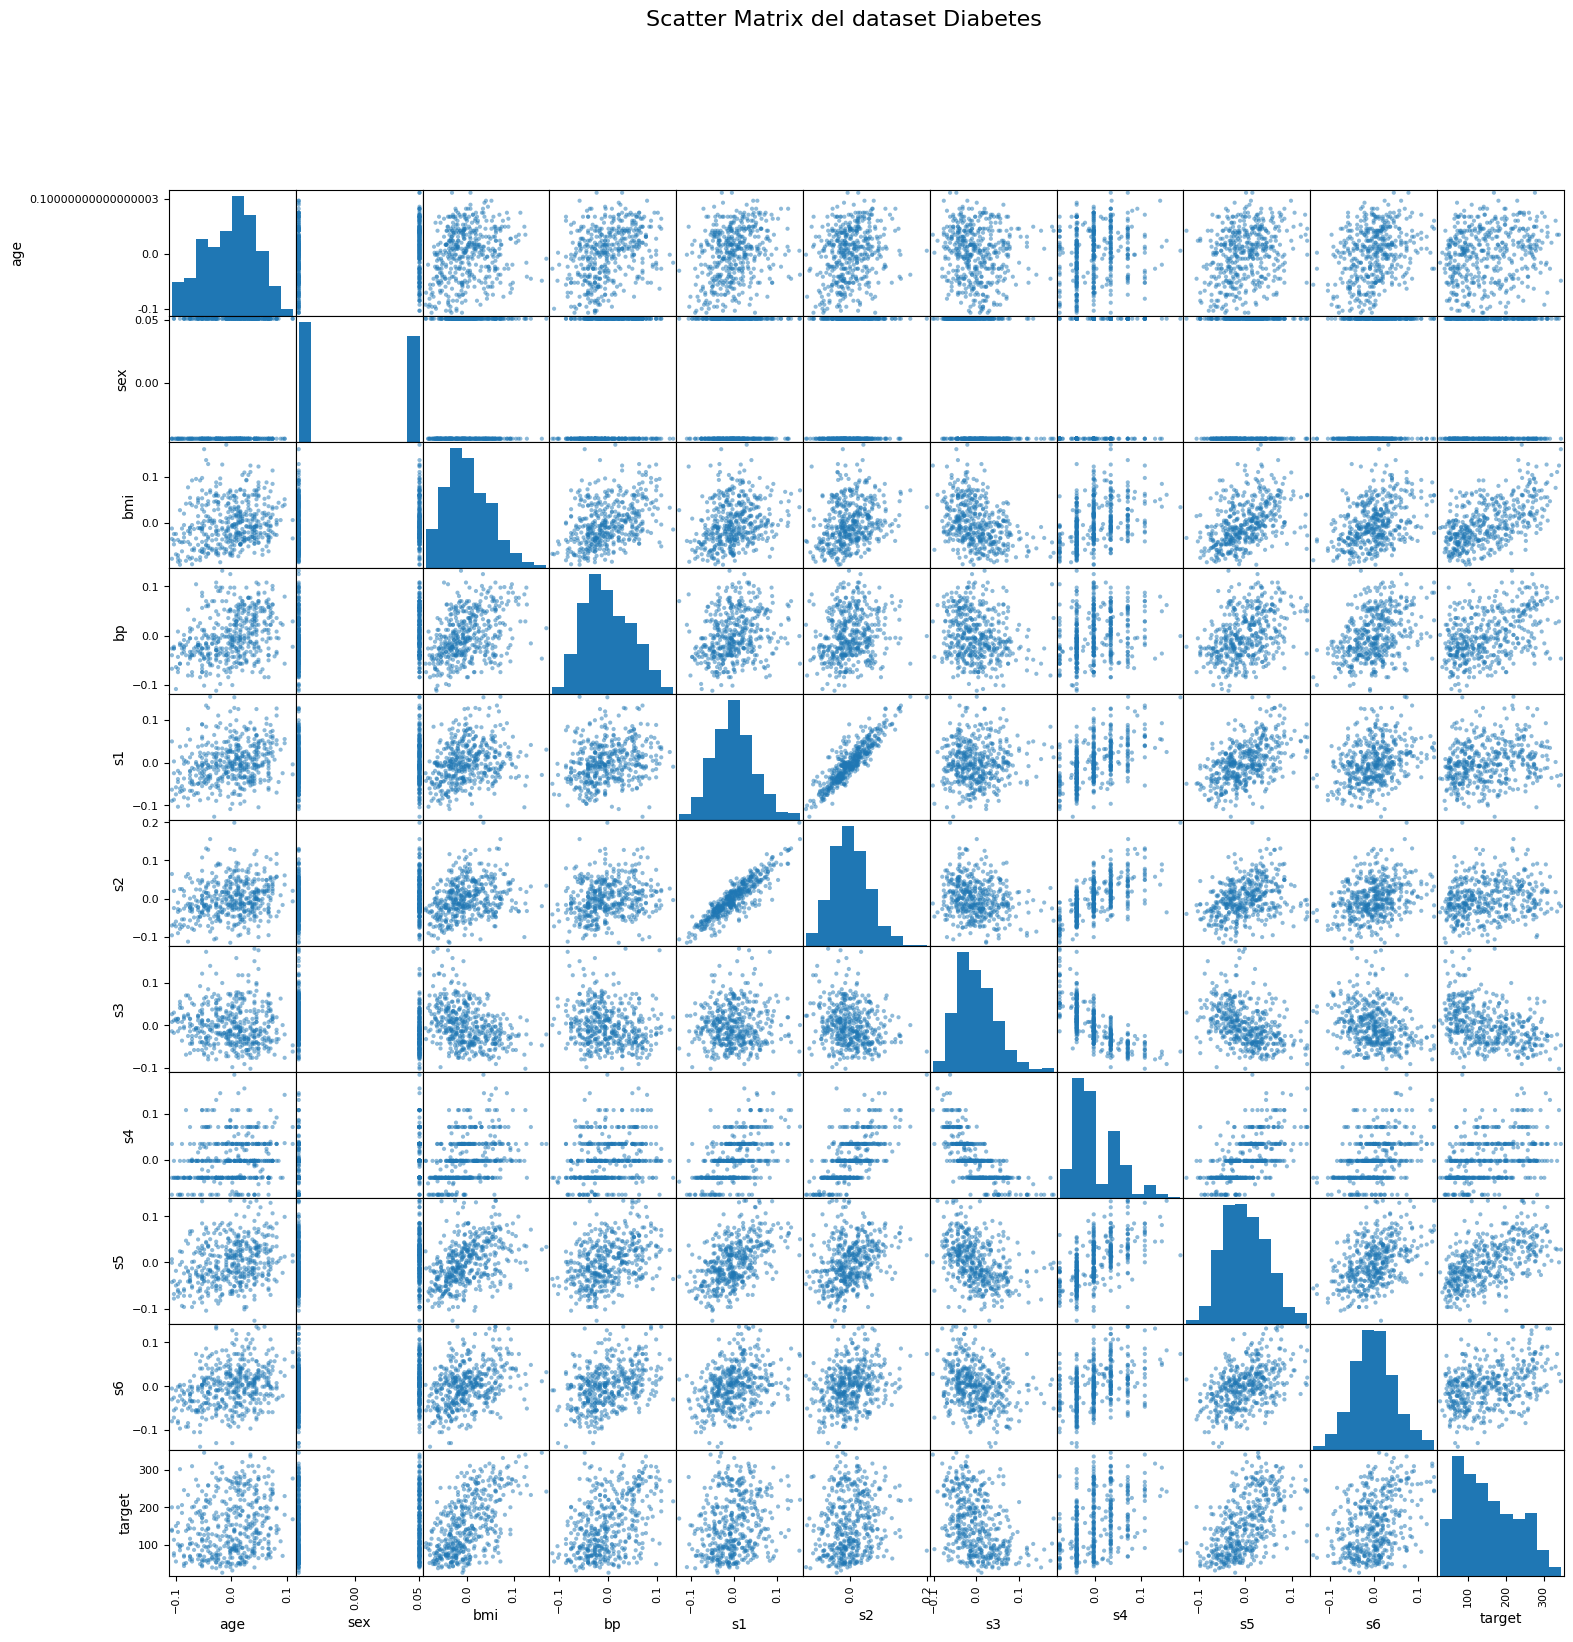

In [8]:

scatter_matrix(
    df,
    figsize=(18, 18),
    diagonal="hist",
    alpha=0.5
)

plt.suptitle("Scatter Matrix del dataset Diabetes", fontsize=16)
plt.show()

In [10]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Dimensioni X_train:", X_train.shape)
print("Dimensioni X_test:", X_test.shape)
print("Dimensioni y_train:", y_train.shape)
print("Dimensioni y_test:", y_test.shape)

Dimensioni X_train: (353, 10)
Dimensioni X_test: (89, 10)
Dimensioni y_train: (353,)
Dimensioni y_test: (89,)


In [12]:
models = {
    "Regressione Lineare": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Ridge": Ridge(),
    "Lasso": Lasso()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: addestramento completato")

Regressione Lineare: addestramento completato
Decision Tree: addestramento completato
Ridge: addestramento completato
Lasso: addestramento completato


In [14]:

kf = KFold(n_splits=5, shuffle=True, random_state=42)


for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_mean_squared_error"
    )

    print(f"{name}")
    print(f"NMSE per ogni fold: {scores}")
    print(f"NMSE medio: {scores.mean():.4f}")
    print()

Regressione Lineare
NMSE per ogni fold: [-2848.75070009 -3221.81099199 -2813.57235224 -2965.89557671
 -3520.68069731]
NMSE medio: -3074.1421

Decision Tree
NMSE per ogni fold: [-3746.85915493 -7410.33802817 -7301.46478873 -6590.82857143
 -7766.27142857]
NMSE medio: -6563.1524

Ridge
NMSE per ogni fold: [-3215.62363311 -4357.05384007 -2924.03537776 -3573.42211045
 -4037.3444891 ]
NMSE medio: -3621.4959

Lasso
NMSE per ogni fold: [-3627.46622075 -4612.50984851 -3141.20399032 -3857.64930359
 -4545.09768357]
NMSE medio: -3956.7854



In [15]:
results = {}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_mean_squared_error"
    )

    results[name] = scores.mean()

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Modello", "NMSE medio"]
)

results_df = results_df.sort_values(
    by="NMSE medio",
    ascending=False
)

print(results_df.to_string(index=False))

best_model_name = results_df.iloc[0]["Modello"]
best_model = models[best_model_name]

print("\nModello migliore:", best_model_name)

            Modello   NMSE medio
Regressione Lineare -3074.142064
              Ridge -3621.495890
              Lasso -3956.785409
      Decision Tree -6563.152394

Modello migliore: Regressione Lineare


In [17]:
ridge = Ridge()

param_grid = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    cv=kf,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train, y_train)

print("Miglior valore di alpha:", grid_search.best_params_)
print("Miglior NMSE medio:", grid_search.best_score_)

best_ridge = grid_search.best_estimator_

Miglior valore di alpha: {'alpha': 0.001}
Miglior NMSE medio: -3072.383733472776


In [19]:
y_pred = best_ridge.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Valutazione finale del modello Ridge ottimizzato")
print(f"MSE sul Test Set: {mse:.4f}")
print(f"R² sul Test Set: {r2:.4f}")

Valutazione finale del modello Ridge ottimizzato
MSE sul Test Set: 2895.8212
R² sul Test Set: 0.4534


Nel complesso, il modello presenta una capacità predittiva moderata, riuscendo a individuare parte delle relazioni tra le variabili indipendenti e la target, pur mantenendo un margine di errore significativo.

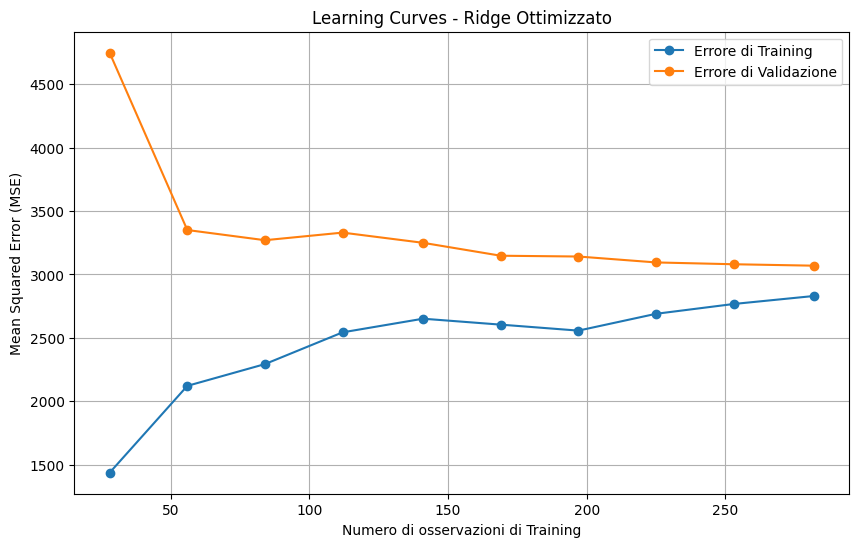

In [21]:
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_ridge,
    X=X_train,
    y=y_train,
    cv=kf,
    scoring="neg_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mse = -train_scores.mean(axis=1)
val_mse = -val_scores.mean(axis=1)

plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    train_mse,
    marker="o",
    label="Errore di Training"
)

plt.plot(
    train_sizes,
    val_mse,
    marker="o",
    label="Errore di Validazione"
)

plt.title("Learning Curves - Ridge Ottimizzato")
plt.xlabel("Numero di osservazioni di Training")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True)
plt.show()


L'errore di Training aumenta progressivamente con il numero di osservazioni, mentre l'errore di Validazione diminuisce.

Le due curve tendono ad avvicinarsi all'aumentare della dimensione del Training Set, mostrando una differenza relativamente contenuta nella parte finale del grafico.

Questo comportamento suggerisce che il modello non presenta problemi evidenti di overfitting, poiché la differenza tra le prestazioni di Training e Validazione si riduce progressivamente.

Entrambi gli errori si stabilizzano su valori non trascurabili, suggerendo una possibile componente di bias elevato e una capacità limitata di rappresentare completamente le relazioni tra le variabili.

Il modello Ridge ottimizzato mostra predittività moderata, coerentemente con il valore di R² pari a 0.4534 ottenuto sul Test Set.

Varianza spiegata da PC1: 0.3983979628424788
Varianza spiegata da PC2: 0.14697332803038993
Varianza totale spiegata: 0.5453712908728687


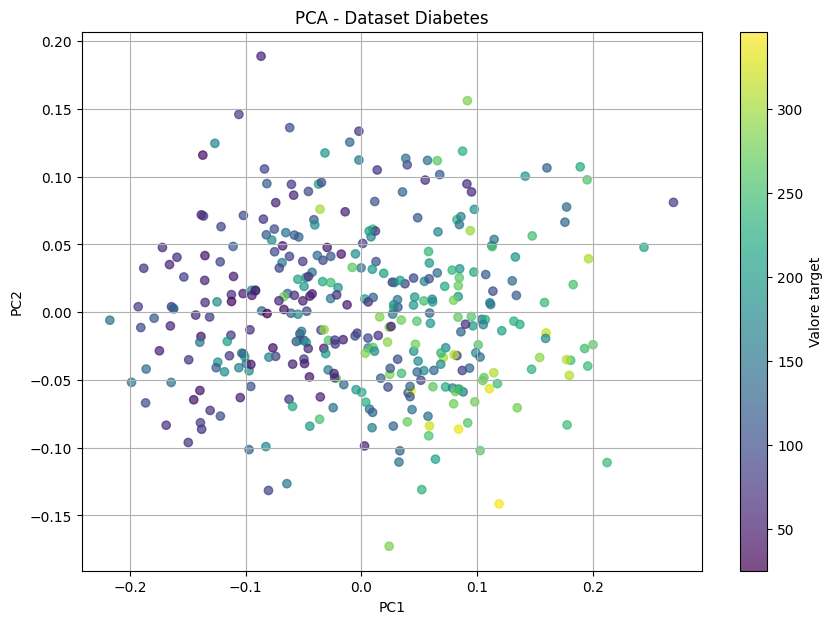

In [23]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train)

X_test_pca = pca.transform(X_test)

print("Varianza spiegata da PC1:", pca.explained_variance_ratio_[0])
print("Varianza spiegata da PC2:", pca.explained_variance_ratio_[1])
print("Varianza totale spiegata:", sum(pca.explained_variance_ratio_))

plt.figure(figsize=(10, 7))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="viridis",
    alpha=0.7
)

plt.colorbar(label="Valore target")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Dataset Diabetes")
plt.grid(True)
plt.show()

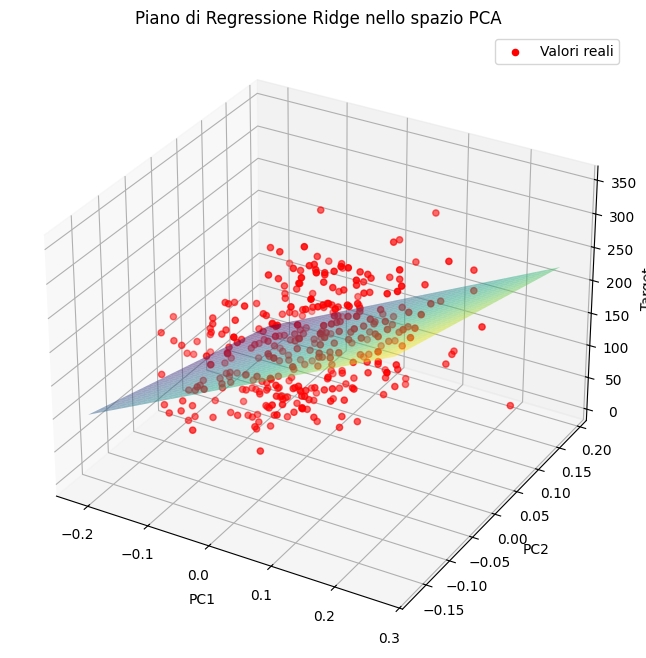

In [24]:
ridge_pca = Ridge(alpha=grid_search.best_params_["alpha"])

ridge_pca.fit(X_train_pca, y_train)

pc1_range = np.linspace(
    X_train_pca[:, 0].min(),
    X_train_pca[:, 0].max(),
    30
)

pc2_range = np.linspace(
    X_train_pca[:, 1].min(),
    X_train_pca[:, 1].max(),
    30
)

PC1, PC2 = np.meshgrid(pc1_range, pc2_range)

grid_points = np.column_stack((PC1.ravel(), PC2.ravel()))

Z = ridge_pca.predict(grid_points)
Z = Z.reshape(PC1.shape)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    PC1,
    PC2,
    Z,
    cmap="viridis",
    alpha=0.5
)

ax.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    y_train,
    color="red",
    s=20,
    label="Valori reali"
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("Target")

ax.set_title("Piano di Regressione Ridge nello spazio PCA")
ax.legend()

plt.show()